In [1]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tools import add_constant
#from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from statsmodels.miscmodels.ordinal_model import OrderedModel

## Importing the data

In [2]:
plans = pd.read_csv("ks_wichita_2023_01_26.csv", low_memory=False)
df = pd.DataFrame(plans)

In [3]:
dataDict = pd.read_excel("Data Dictionary.xlsx")

## Initial analysis and summary

In [4]:
df.head()

,raw_row_number,date,time,location,lat,lng,geocode_source,subject_age,subject_race,subject_sex,...,violation,citation_issued,outcome,posted_speed,vehicle_color,vehicle_make,vehicle_model,vehicle_year,raw_defendant_race,raw_defendant_ethnicity
0,24860,2006-01-01,64800,"1400 N MINNEAPOLIS, WICHITA, KS",37.708126,-97.315285,GM,NaN,unknown,NaN,...,ALLEY PARKING,True,citation,NaN,BURGUNDY OR MAROON,PONTIAC,NaN,NaN,U,NaN
1,28588,2006-01-01,64800,"1410 S GLENDALE AVE, WICHITA, KS, 67218",37.666980,-97.277571,GM,NaN,unknown,NaN,...,PARK IN FIRE LANE,True,citation,NaN,GRAY,DODGE,INTREPID,NaN,U,NaN
2,25907,2006-01-01,64800,"5300 S MOSLEY ST, WICHITA, KS, 67216",37.599499,-97.326801,GM,NaN,unknown,NaN,...,PARK W/IN 8' OF PRIVATE DRIVE,True,citation,NaN,BROWN,OLDSMOBILE,NaN,NaN,U,NaN
3,80832,2006-01-01,64800,"E CENTRAL AVE, WICHITA, KS, 67214",37.693630,-97.315165,GM,24.0,white,male,...,NO DRIVER'S LICENSE; YIELD ROW-LEFT TURN,True,citation,NaN,WHITE,MERCURY,NaN,NaN,W,N
4,80815,2006-01-01,64800,NaN,NaN,NaN,NaN,25.0,black,female,...,NO DRIVER'S LICENSE,True,citation,NaN,GRAY,CHEVROLET,NaN,NaN,B,N


In [5]:
preview = []

cols = df.columns

for col in cols:
    idx = dataDict.index[dataDict['Column name'].str.lower().str.strip() == col.lower().strip()]
    try:
        preview.append([col, df[col].dtypes, df[col].head(1).iloc[0],df[col].unique().size,
                        df[col].unique(), dataDict.loc[idx[0], 'Column meaning']])
    except IndexError:
        print(f"{col} not in df")
previewDf = pd.DataFrame(preview, columns = ['Variable', 'dtype', 'example', 'number of uniques', 'uniques', 'definition'])
previewDf

raw_defendant_race not in df
raw_defendant_ethnicity not in df


,Variable,dtype,example,number of uniques,uniques,definition
0,raw_row_number,object,24860,1030376,"[24860, 28588, 25907, 80832, 80815, 24485, 274...",An number used to join clean data back to the ...
1,date,object,2006-01-01,4884,"[2006-01-01, 2006-01-02, 2006-01-03, 2006-01-0...","The date of the stop, in YYYY-MM-DD format. So..."
2,time,int64,64800,1440,"[64800, 64860, 66420, 67500, 67800, 68100, 690...","The 24-hour time of the stop, in HH:MM format."
3,location,object,"1400 N MINNEAPOLIS, WICHITA, KS",47801,"[1400 N MINNEAPOLIS, WICHITA, KS, 1410 S GLEND...",The freeform text of the location. Occasionall...
4,lat,float64,37.708126,33996,"[37.7081257, 37.6669801, 37.599499, 37.6936296...",The latitude of the stop. If not provided by t...
5,lng,float64,-97.315285,30997,"[-97.3152848, -97.277571, -97.326801, -97.3151...",The longitude of the stop. If not provided by ...
6,geocode_source,object,GM,3,"[GM, nan, SU]",The geocoding service used to geocode the addr...
7,subject_age,float64,NaN,101,"[nan, 24.0, 25.0, 42.0, 33.0, 17.0, 18.0, 16.0...",The age of the stopped subject. When date of b...
8,subject_race,object,unknown,7,"[unknown, white, black, nan, asian/pacific isl...",The race of the stopped subject. Values are st...
9,subject_sex,object,NaN,3,"[nan, male, female]",The recorded sex of the stopped subject.


## Dataset cleaning

In [6]:
df = df[df['type'] == 'vehicular'] # want only vehicular citations
df = df.drop(columns = ['raw_row_number','lat', 'lng', 'geocode_source', 'citation_issued', 'outcome', 'vehicle_year', 'posted_speed']) # drop unwanted cols
df['year'] = pd.to_datetime(df['date']).dt.year # change dates to date/time type
df = df[df['year'] >= 2018] # filter years for greater than 2018

In [7]:
# Convert seconds to timedelta
td = pd.to_timedelta(df["time"], unit="s")

# Extract just HH:MM:SS from timedelta
df["time_str"] = (td.dt.components.hours.astype(str).str.zfill(2) + ":" +
                  td.dt.components.minutes.astype(str).str.zfill(2) + ":" +
                  td.dt.components.seconds.astype(str).str.zfill(2))

# Combine date + formatted time
df["datetime"] = pd.to_datetime(
    df["date"] + " " + df["time_str"],
    format="%Y-%m-%d %H:%M:%S"
)

# Extract useful components
df["hour"] = df["datetime"].dt.hour
df["day_of_week"] = df["datetime"].dt.dayofweek
df["month"] = df["datetime"].dt.month


In [8]:
# make location into zip
df['zip'] = df['location'].str.split(', ').str[-1]

In [9]:
# notes:
# from what i can tell, raw_defendant_ethnicity doesn't provide any new/useful information and as of now is 100% empty so dropping
# subject_race and raw_defendant_race are the same but subject_race is initial (W) rather than the whole word (White)
# will use subject_race and drop raw_defendant_race

df = df.drop(columns = ['raw_defendant_ethnicity', 'raw_defendant_race'])

In [10]:
# cleaning the vehicle make column 

# noted that when a value had | in it with multiple makes (multi‑value field), the first make was chosen 

suffixes = ['CORP.', 'CO.', 'INC.', 'LTD.', 'MFG.', 'INTL.']

legacies = ["PONTIAC", "OLDSMOBILE", "PLYMOUTH", "SATURN", "DATSUN", "GEO", "HUMMER", "ROVER",
            "AUSTIN", "MG", "DAEWOO", "SUZULIGHT", "AVIA", "MURENA", "PEACE", "BRONCCO", "SABRA", "SCION", "SAAB", "VICTORIA",
           "AURORA", "MISTRAL", "PETERSON", "PANTHER"]

motorcycles = ["HARLEY-DAVIDSON", "DUCATI", "YAMAHA MOTOR CO.,", "KAWASAKI", "MOTO GUZZI", "INDIAN MOTORCYCLE", "VICTORY MOTORCYCLES",
               "INDIAN", "BUELL", "KTM", "TRIUMPH", "CAN-AM", "BASHAN", "HUFFY", "MINISCOOTER", "TAOTAO", "CHAPPY", "EAGLE",
              "STERLING INDUSTRIAL", "AURANTHETIC CHARGER", "MIDAS INTL", "RAMLIN", "SILVER BULLET", "BAJA" ]

# includes heavy trucks, trailers, industrial vehicles, buses, coaches and RVs
trailers = ["INTERNATIONAL COACH","UTILITY TRAILER", "LOAD RITE TRAILERS","INTERNATIONAL TRAILER", "SUN BLAZER TRAVEL TRAILER", "U-HAUL",
            "PELICAN ALUMINUM", "FRANCIS TRAVEL TRAILER","ALLEGRO MOTOR HOME", "TOYOCAR VAN CONTAINER TRAILER", "BUSHCRAFT TRAILER", 
            "FORTE TRAILER", "TRAILER COACH METAL SPEC.", "ELLIOTT MOBILE HOME", "LINCOLN ELECTRIC", "PETER PIRSCH & SONS", "FLXIBLE", "GILL MFG",
            "HEIL", "INTERCONSULT MFG", "GRONEWEGEN B.V.", "OTTERBACHER MFG", "SUBURBAN MOTORS", "FREIGHTLINER", 
            "PETERBILT", "MACK TRUCKS", "WESTERN STAR", "OSHKOSH MOTOR TRUCK", "UTILIMASTER",
            "GRUMMAN‑OLSEN", "SCHNURE HO' TRAILER", "P. J. TRAILER MFG", "EMPIRE TRAILER", "DOOLITTLE", "OTTERBACHER MFG", 
            "INTERCONSULT MFG", "GRONEWEGEN B.V.", "BLUEBIRD", "BLUE RIBBON COACH", "MOTOR COACH INDS.","COACH CRAFT", "JAYCO", "ALLEGRO MOTOR HOME",
            "HINO", "KENWORTH NORTHWEST", "KENWORTH MOTOR TRUCK", "INTERNATIONAL HARVESTER", "LANDCRAFT", "INTERNATIONAL INDS", "GRUMANN-OLSEN"]


def cleaned(row):
    row = str(row).strip()

    # if an unk/na, normalize all to the same category
    if pd.isna(row) or row.lower() in ["nan", "na", "unknown", "unk", "uk", "NA"]: # normalized all missing/unknown to UNKNOWN
        return 'UNKNOWN'

    # remaining are values that need cleaning
    row = row.split("(")[0].strip() # eg. JEEP (1989 TO PRESENT) becomes JEEP
    row = row.split("|")[0].strip()# eg. DODGE|HONDA becomes DODGE 
    
    if any(suffix in row for suffix in suffixes):
        row = " ".join(row.split(" ")[:-1]).strip()
        
    if any(legacy in row for legacy in legacies):
        row = 'LEGACY'

    if any(motorcycle in row for motorcycle in motorcycles):
        row = 'MOTORCYCLE'

    if any(trailer in row for trailer in trailers):
        row = 'TRAILER'

    replace = {
        "MERCEDES-BENZ": "MERCEDES",
        "MINI COOPER": "MINI",
        "LINCOLN-CONTINENTAL": "LINCOLN",
        "RANGE ROVER OF NORTH AMERICA": "LAND ROVER",
        "SMART CAR": "SMART",
        "SMARTLEE": "SMART",
        "PIAGGO": "PIAGGIO",
        "SUZULIGHT SU": "SUZULIGHT",
        "GENERAL MOTORS": "GM",
        "KIA MOTORS": "KIA",
        "PETERBILT MOTORS": "PETERBILT",
        "BUELL MOTOR": "BUELL",
        "MUSTANG": "FORD",
        "COOPER": "MINI",
        "PASSPORT":"HONDA",
        "CHARGER":"DODGE",
        "AVENGER":"DODGE",
        "TRANSIT":"FORD",
        "NA": "UNKNOWN",
        "N/A": "UNKNOWN",

    }
    
    return replace.get(row, row)

df['vehicle_make_clean'] = df['vehicle_make'].apply(cleaned)

In [11]:
# keeping dictionary at make level for clarity and simplicity, model would be used for cost/risk prediction, insurance, or fine‑grained segmentation
# color would be for behavior or aesthetic corrections

tier_map = {
    # Economy brands
    "CHEVROLET": "ECONOMY",
    "FORD": "ECONOMY",
    "TOYOTA": "ECONOMY",
    "HONDA": "ECONOMY",
    "DODGE": "ECONOMY",
    "NISSAN": "ECONOMY",
    "HYUNDAI": "ECONOMY",
    "KIA": "ECONOMY",
    "CHRYSLER": "ECONOMY",
    "BUICK": "ECONOMY",
    "MAZDA": "ECONOMY",
    "SUBARU": "ECONOMY",
    "MITSUBISHI": "ECONOMY",
    "SUZUKI": "ECONOMY",
    "ISUZU": "ECONOMY",
    "GM": "ECONOMY",   # collapsed General Motors

    # Mid-tier brands
    "VOLKSWAGEN": "MID",
    "MERCURY": "MID",
    "ACURA": "MID",
    "LEXUS": "MID",
    "INFINITI": "MID",
    "VOLVO": "MID",
    "AUDI": "MID",
    "MINI": "MID",
    "SMART": "MID",

    # Luxury brands
    "BMW": "LUXURY",
    "MERCEDES": "LUXURY",
    "CADILLAC": "LUXURY",
    "LINCOLN": "LUXURY",
    "JAGUAR": "LUXURY",
    "PORSCHE": "LUXURY",
    "FIAT": "LUXURY",        # borderline, but often treated as boutique
    "MASERATI": "LUXURY",
    "ALFA ROMEO": "LUXURY",
    "ROLLS-ROYCE": "LUXURY",
    "LOTUS": "LUXURY",
    "LAMBORGHINI": "LUXURY",
    "PIAGGIO": "LUXURY",     # scooters, but boutique
    "TRANSIT": "FORD",       # normalized earlier
    "CHARGER": "DODGE",      # normalized earlier

    # Buckets
    "LEGACY": "LEGACY",        # defunct car brands
    "MOTORCYCLE": "MOTORCYCLE",
    "TRAILER": "TRAILER",
    "UNKNOWN": "UNKNOWN"
}
df['vehicle_tier'] = df['vehicle_make_clean'].map(tier_map).fillna("UNKNOWN")

In [12]:
df = df.drop(columns = ["date", "time","location","type","vehicle_color","vehicle_make", "vehicle_model","datetime", "vehicle_make_clean"])

In [13]:
# get all unique violations to bin them

df['violation_norm'] = df['violation'].astype(str).apply(lambda x: re.sub(r"[|;/]", "|", x)) # normalize the deliminators to |
df['violation_list'] = df['violation_norm'].str.split("|")
df['violation_list'] = df['violation_list'].apply(lambda lst: [v.strip().upper() for v in lst if v.strip()])
all_violations = set(v for lst in df['violation_list'] for v in lst)
print(len(all_violations))


434


In [14]:
# create violation buckets (vioLAtion severities)
# when cleaning, if multipke violations will choose the first
# multiple are listed with | or ; or / or -

# severity ranking will be:
# High - immediate danger to life/legal consequences
# Medium severity - risky behavior but less catastrophic
# Low severity - administrative, parking, or minor equipment issues.

def score_violation(v):
    
    # High severity
    if re.search(r"DUI|DRUG|ALCOHOL|MARIJUANA|CONTROLLED SUBSTANCE|HIT AND RUN|HIT & RUN|ASSAULT|BATTERY|WEAPON|FIREARM|ELUDE|EVADE|REVOKED|NO DRIVER'S LICENSE|UNLICENSED|UNINSURED|FALSE INFORMATION|FRAUD|CRIMINAL", v):
        return 3
    
    # Medium severity
    if re.search(r"SPEED|SCHOOL ZONE|TEXTING|INATTENTIVE|RECKLESS|CARELESS|FOLLOW TOO CLOSE|UNSAFE|FAIL TO YIELD|FAIL TO REDUCE|STOP-SCHOOL BUS|GO AROUND RR GATE|DRIVE WRONG WAY|DRIVE OVER FIRE HOSE|SECURE LOAD|PROJECTING LOAD", v):
        return 2
    
    # Low severity
    if re.search(r"PARK|METER|TAG|PERMIT|PLACARD|SIGNAL|LIGHT|LAMP|WINDSHIELD|MIRROR|MUFFLER|EQUIPMENT|CURB|HYDRANT|SIDEWALK|PRIVATE LOT|NO TURN|NO U TURN|PLAYGROUND|SOUND|AMPLIFICATION|SOLICIT|BIKE|SCOOTER", v):
        return 1

    return 1 # default if all else fails
    
def worst_violation(vio_string):
    if pd.isna(vio_string):
        return 0

    cleaned = re.sub(r'[|;/]', '|', str(vio_string))
    
    violations = [v.strip() for v in cleaned.split("|") if v.strip()]
    
    # Assign severity, default to 1 if not found
    scored = [(v, score_violation(v)) for v in violations]

    # Pick violation with max severity
    worst = max(scored, key=lambda x: x[1])
    return worst[1]

df.loc[df['violation'].index, 'violation_severity'] = df['violation'].apply(worst_violation)

In [15]:
# clean dispositions column
df['disposition_norm'] = df['disposition'].astype(str).apply(lambda x: re.sub(r"[|;/]", "|", x)) # normalize the deliminators to |
df['disposition_list'] = df['disposition_norm'].str.split("|")
df['disposition_list'] = df['disposition_list'].apply(lambda lst: [v.strip().upper() for v in lst if v.strip()])
all_violations = set(v for lst in df['disposition_list'] for v in lst)
print(len(all_violations))
print(all_violations)

18
{'DISMISSED WITH PREJUDICE', 'PRODUCED LICENSE', 'DISMISSED WITHOUT PREJUDICE', 'GUILTY, FINES ABATED', 'AMENDED CHARGE', 'NOT GUILTY', 'GUILTY (IVR)', 'NA', 'DIVERSION', 'REPAIRED', 'DISMISSED', 'HAD DRIVERS LICENSE', 'PROVIDED PROOF', 'NOLLO CONTENDRE', 'GUILTY', 'NAN', 'DEFERRED ACCEPTED', 'NOLLE PROS'}


In [16]:
df = df.dropna(subset=['disposition'])

In [17]:
# create disposition binning (disposition_Severity)

"""

two bins align with Kansas law — conviction vs non‑conviction.
There isn’t a single Kansas statute that defines “disposition severity” for outcomes like dismissed, guilty, diversion, nolle pros, etc. 
Instead, these are standard court disposition codes used across U.S. courts to record the final status of a case. In Kansas, dispositions 
are governed by the Kansas Code of Criminal Procedure (K.S.A. Chapter 22) and related statutes (e.g., diversion agreements under K.S.A. 22‑2909,
dismissals under K.S.A. 60‑241). These codes don’t have a numeric severity scale in law; severity is usually inferred by analysts based on 
whether the disposition results in conviction, dismissal, diversion, or amendment


References for Disposition Codes
- Dismissals → Covered under K.S.A. 60‑241 (civil procedure, voluntary and involuntary dismissals).
- Diversion agreements → Defined in K.S.A. 22‑2909, allowing certain cases to be diverted from prosecution if conditions are met.
- Nolle prosequi (NOLLE PROS) → A prosecutor’s formal decision to drop charges; recognized in Kansas criminal procedure.
- Nolo contendere (NOLLO CONTENDRE) → A plea where the defendant does not contest the charge; treated like a guilty plea for sentencing.
- Deferred acceptance / diversion → Case is paused or diverted; if conditions are met, charges may be dismissed.
- Guilty / Not Guilty → Standard criminal dispositions under Kansas criminal procedure.
- Amended charge / fines abated / produced license / repaired → Administrative or corrective dispositions, often tied to municipal or traffic courts.

Disposition severity was collapsed to binary (conviction vs non‑conviction) to avoid quasi‑separation in MNLogit. 
Future work may revisit multinomial models if diversion cases are more frequent.”

"""

disposition_severity = {

    # high severity - conviction or an admission of guilt
    
    "GUILTY": 1, # full convistion, max consequence
    "GUILTY (IVR)": 1, # guilty via in‑vehicle recording or similar process, still a conviction.
    "GUILTY, FINES ABATED": 1, # conviction, but penalty reduced
    "NOLLO CONTENDRE": 1, # (no contest) → treated as guilty for sentencing, though not an admission.

    # low severity and medium severity - 
    # low severity - dismissal or compliance shown
    # medium severity - - conditional resolution or diversion
    
    "NOT GUILTY": 0, #acquittal, no conviction
    "DISMISSED": 0, # case dropped
    "DISMISSED WITH PREJUDICE": 0, # permanently dismissed, can't be refiled
    "DISMISSED WITHOUT PREJUDICE": 0, # dismissed but can be refiled
    "NOLLE PROS": 0, # (nolle prosequi) → prosecutor declines to pursue; case dropped
    "PROVIDED PROOF": 0, # defendant showed compliance (e.g., insurance, license)
    "PRODUCED LICENSE": 0, # compliance shown
    "HAD DRIVERS LICENSE": 0, # compliance shown
    "REPAIRED": 0, # equipment violation fixed
    "DEFERRED ACCEPTED": 0, # deferred judgment, accepted by court; conviction avoided if conditions met
    "DIVERSION": 0, # alternative program instead of conviction; moderate consequence
    "AMENDED CHARGE": 0, # charge reduced or changed; consequence depends on new charge

}

def worst_disposition(vio_string):
    if pd.isna(vio_string):
        return 0
    cleaned = re.sub(r'[|;/]', '|', vio_string)
    violations = [v.strip() for v in vio_string.split("|")if v.strip()]
    
    # Assign severity, default to 1 if not found
    scored = [(v, disposition_severity.get(v,1)) for v in violations]

    # Pick violation with max severity
    worst = max(scored, key=lambda x: x[1])
    return worst[1]


df.loc[df['disposition'].index, 'disposition_severity'] = df['disposition'].apply(worst_disposition)


In [18]:
# zip bucketing into city locations

"""
Zip breakdown:
https://usmapguide.com/kansas/wichita-zip-code-map/
https://zipcodes-us.com/zip/ks/wichita

- Central Wichita ZIPs (67202, 67203, 67214) cover downtown and historic districts.
- East Wichita ZIPs (67206, 67207, 67208, 67226, 67228, 67230) cover suburban growth and retail corridors.
- West Wichita ZIPs (67212, 67213, 67235) cover residential and newer developments.
- South Wichita ZIPs (67210, 67211, 67216, 67217) cover industrial and older residential areas.
- North Wichita ZIPs (67204, 67219, 67220, 67223) cover established neighborhoods and suburban expansion.

"""
central = ['67202', '67203', '67214']
east = ['67206', '67207', '67208', '67226', '67228', '67230']
west = ['67212', '67213', '67235']
south = ['67210', '67211', '67216', '67217']
north = ['67204', '67219', '67220', '67223']

df['city_location'] = np.where(df['zip'].isin(central), 'central', 
                               np.where(df['zip'].isin(east), 'east',
                               np.where(df['zip'].isin(west), 'west',
                               np.where(df['zip'].isin(south), 'south',
                               np.where(df['zip'].isin(north), 'north', 'unknown')))))

In [19]:
df['subject_race'] = df['subject_race'].fillna('unknown')

In [20]:
# Age categories with Unknown
bins = [0, 24, 34, 54, 64, 120]
labels = ['16-24', '25-34', '35-54', '55-64', '65+']
df['age_category'] = pd.cut(df['subject_age'], bins=bins, labels=labels, right=True)
df['age_category'] = df['age_category'].cat.add_categories('Unknown').fillna('Unknown')

# Sex and race with Unknown
df['subject_sex'] = df['subject_sex'].astype('category').cat.add_categories('Unknown').fillna('Unknown')

## Transformations and their reasonings

Text(0.5, 0, 'year')

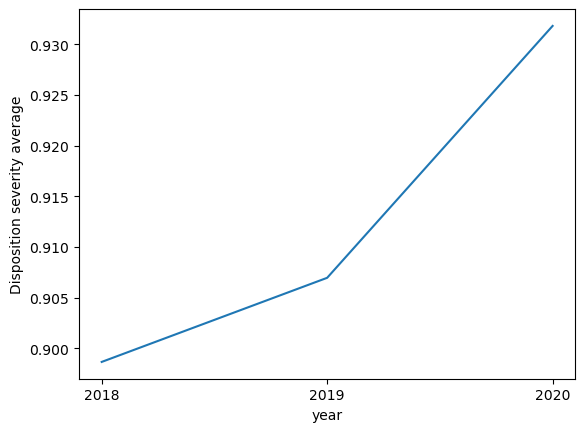

In [21]:
# mean dispositions for each year shows a severe jump from 2019 to 2020 so made year a categorical variable
workingWith = df.copy()
mean2018 = workingWith[workingWith['year'] == 2018]
mean2018sev = mean2018['disposition_severity'].mean()

mean2019 = workingWith[workingWith['year'] == 2019]
mean2019sev = mean2019['disposition_severity'].mean()

mean2020 = workingWith[workingWith['year'] == 2020]
mean2020sev = mean2020['disposition_severity'].mean()

means = [mean2018sev, mean2019sev, mean2020sev]

plt.plot(['2018', '2019', '2020'], means)
plt.ylabel('Disposition severity average')
plt.xlabel('year')


Text(0, 0.5, 'Disposition severity average')

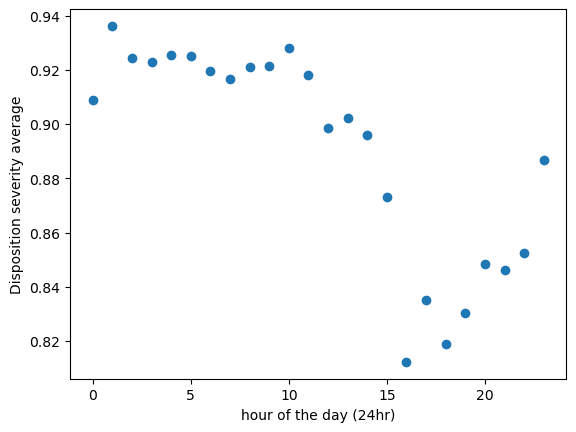

In [22]:
# shows a sinusoidal pattern so did geometric transformations

hours = workingWith['hour'].unique()

hourVals = []
for hour in hours:
    mean = workingWith[workingWith['hour'] == hour]
    hourVals.append(mean['disposition_severity'].mean())

plt.scatter(hours, hourVals)   
plt.xlabel('hour of the day (24hr)')
plt.ylabel('Disposition severity average')

Text(0, 0.5, 'Disposition severity average')

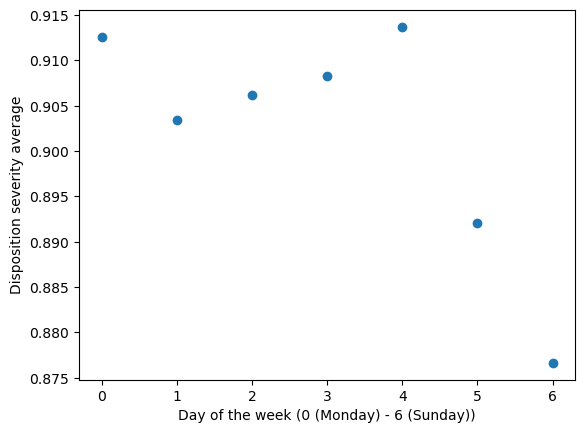

In [23]:
# disposition severity by days of the week - sinusoidal pattern handled with geometric transformation
days = workingWith['day_of_week'].unique()

Vals = []
for day in days:
    mean = workingWith[workingWith['day_of_week'] == day]
    Vals.append(mean['disposition_severity'].mean())

plt.scatter(days, Vals)
plt.xlabel('Day of the week (0 (Monday) - 6 (Sunday))')
plt.ylabel('Disposition severity average')

Text(0, 0.5, 'Disposition severity average')

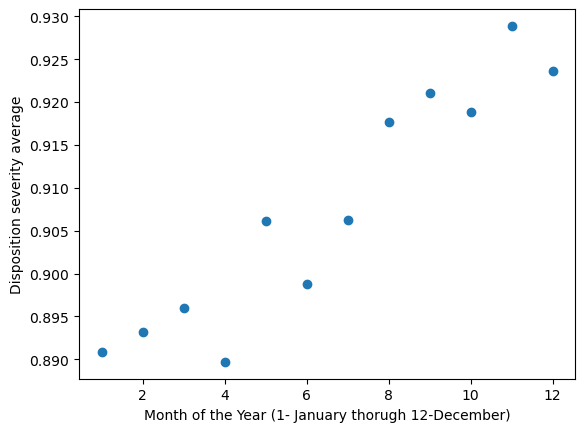

In [24]:
# average disposition severity by month of the year - more sinusoidal than linear so did geometric transformation
months = workingWith['month'].unique()

Vals = []
for month in months:
    mean = workingWith[workingWith['month'] == month]
    Vals.append(mean['disposition_severity'].mean())

plt.scatter(months, Vals) 
plt.xlabel('Month of the Year (1- January thorugh 12-December)')
plt.ylabel('Disposition severity average')

Text(0, 0.5, 'Disposition severity average')

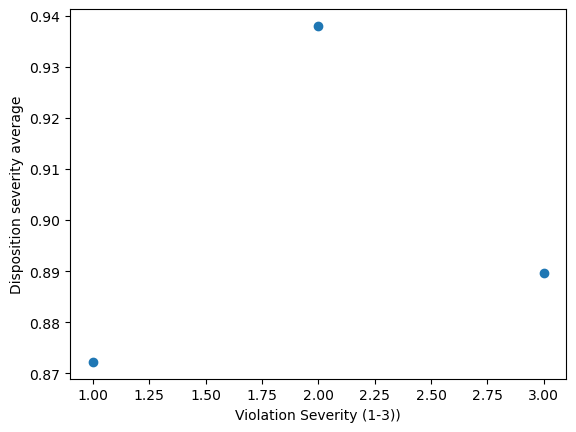

In [25]:
# nonlinear relation (violation 2 has the most disposition severities) so turned categorical to handle this
severity = workingWith['violation_severity'].unique()

Vals = []
for sev in severity:
    mean = workingWith[workingWith['violation_severity'] == sev]
    Vals.append(mean['disposition_severity'].mean())

plt.scatter(severity, Vals)  
plt.xlabel('Violation Severity (1-3))')
plt.ylabel('Disposition severity average')

In [26]:
# Polynomial terms for violation severity produced unstable estimates due to limited distinct values. 
# Severity will instead be modeled as categorical levels to avoid collinearity

df['violation_severity'] = df['violation_severity'].astype('category')

# Other changes for the model

In [27]:
# reordered categories for race so baseline is white

df['subject_race'] = pd.Categorical(df['subject_race'])
df['subject_race'] = pd.Categorical(
    df['subject_race'],
    categories=['white','black','asian/pacific islander','other','unknown'],
    ordered=False
)


In [28]:
workingWith = df.drop(columns = ['violation','subject_age','disposition','zip', 'violation_norm', 'violation_list', 'disposition_list','disposition_norm'])
workingWith["year_cat"] = workingWith["year"].astype("category")

catVars = workingWith.select_dtypes(include = ['object', 'category']).columns

In [29]:
# cyclic encoding for hour, day of week and month
# Hour (24 hours in a day)
workingWith["hour_sin"] = np.sin(2 * np.pi * workingWith["hour"] / 24)
workingWith["hour_cos"] = np.cos(2 * np.pi * workingWith["hour"] / 24)

# Day of week (7 days)
workingWith["dow_sin"] = np.sin(2 * np.pi * workingWith["day_of_week"] / 7)
workingWith["dow_cos"] = np.cos(2 * np.pi * workingWith["day_of_week"] / 7)

# Month (12 months)
workingWith["month_sin"] = np.sin(2 * np.pi * workingWith["month"] / 12)
workingWith["month_cos"] = np.cos(2 * np.pi * workingWith["month"] / 12)

In [30]:
# dummy the cat
dummies = pd.get_dummies(workingWith[catVars], drop_first=True, dtype = int)
dummies

,subject_race_black,subject_race_asian/pacific islander,subject_race_other,subject_race_unknown,subject_sex_male,subject_sex_Unknown,time_str_00:01:00,time_str_00:02:00,time_str_00:03:00,time_str_00:04:00,...,city_location_south,city_location_unknown,city_location_west,age_category_25-34,age_category_35-54,age_category_55-64,age_category_65+,age_category_Unknown,year_cat_2019,year_cat_2020
929717,0,0,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
929718,0,0,0,1,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
929719,0,0,0,1,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
929720,0,0,0,1,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
929721,0,0,0,1,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1030266,0,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1030277,0,0,0,0,1,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,1
1030305,0,0,0,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
1030346,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1


In [31]:
# check VIF for cats after making into dummies, dropped vars with VIF > 10
vif_data = pd.DataFrame()
vif_data["feature"] = dummies.columns

vif_data["VIF"] = [variance_inflation_factor(dummies.values, i) for i in range(len(dummies.columns))]
print(vif_data)

KeyboardInterrupt: 

In [32]:
result = pd.concat([
    dummies,
    workingWith[["disposition_severity", "hour_sin", "hour_cos", 
                 "month_sin", "month_cos", "dow_sin", "dow_cos"]]
], axis=1)

result.dtypes

subject_race_black                       int64
subject_race_asian/pacific islander      int64
subject_race_other                       int64
subject_race_unknown                     int64
subject_sex_male                         int64
                                        ...   
hour_cos                               float64
month_sin                              float64
month_cos                              float64
dow_sin                                float64
dow_cos                                float64
Length: 1472, dtype: object

## model run

In [33]:
# double checking there are no na vals

nullDf = []
null_data = result.isnull().sum()

# calculate percentages
percentages = (null_data / len(result)) * 100

# Create summary DataFrame
nullDf = pd.DataFrame({'Column': null_data.index,'Count': null_data.values,'Percentage': percentages.values})

print(nullDf.sort_values('Count', ascending=False))

                  Column  Count  Percentage
0     subject_race_black      0         0.0
978    time_str_16:13:00      0         0.0
987    time_str_16:22:00      0         0.0
986    time_str_16:21:00      0         0.0
985    time_str_16:20:00      0         0.0
...                  ...    ...         ...
488    time_str_08:03:00      0         0.0
487    time_str_08:02:00      0         0.0
486    time_str_08:01:00      0         0.0
485    time_str_08:00:00      0         0.0
1471             dow_cos      0         0.0

[1472 rows x 3 columns]


In [34]:
X = result.drop(columns = ['disposition_severity','subject_sex_Unknown','subject_race_unknown'])
y = result['disposition_severity']

X['vehicle_tier_other'] = X['vehicle_tier_MOTORCYCLE'] | X['vehicle_tier_TRAILER'] | X['vehicle_tier_LEGACY']
X = sm.add_constant(X)
reduced_model = sm.GLM(y, X.drop(columns = ['vehicle_tier_MOTORCYCLE','age_category_65+','subject_sex_male','vehicle_tier_TRAILER', 'vehicle_tier_LEGACY']), sm.families.Binomial()).fit()
print(reduced_model.aic, reduced_model.llf)
print(reduced_model.summary())

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/genmod/families/links.py:198: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


KeyboardInterrupt: 

## Running train/test model to measure out of sample predictive performance

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

# 1. Load the cleaned data
df = pd.read_csv("WichitaCleanDf.csv") # or the exact path/filename you saved

# 2. Define X (predictors) and y (outcome)
y = df['disposition_severity']
X = df.drop(columns=['disposition_severity'])

# 3. Add intercept for statsmodels
X = sm.add_constant(X)

# 4. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,      # 25% test, 75% train (change if you like)
    random_state=42,     # for reproducibility
    stratify=y           # keeps outcome class distribution similar in train/test
)

# 5. Fit the binomial GLM on the training data
model = sm.GLM(y_train, X_train, family=sm.families.Binomial()).fit()

print("Training AIC:", model.aic)
print("Training Log-Likelihood:", model.llf)
print(model.summary())

# 6. (Optional) Predict on the test set
y_pred_prob = model.predict(X_test)              # predicted probabilities
y_pred = (y_pred_prob > 0.5).astype(int)         # convert to 0/1 using 0.5 cutoff

Training AIC: 38726.54718191056
Training Log-Likelihood: -19335.27359095528
                  Generalized Linear Model Regression Results                   
Dep. Variable:     disposition_severity   No. Observations:                65122
Model:                              GLM   Df Residuals:                    65094
Model Family:                  Binomial   Df Model:                           27
Link Function:                    Logit   Scale:                          1.0000
Method:                            IRLS   Log-Likelihood:                -19335.
Date:                  Tue, 09 Dec 2025   Deviance:                       38671.
Time:                          12:14:42   Pearson chi2:                 6.45e+04
No. Iterations:                       6   Pseudo R-squ. (CS):            0.03059
Covariance Type:              nonrobust                                         
                                          coef    std err          z      P>|z|      [0.025      0.975]
----------

## Metrics to assess out of sample predictive performance

Accuracy: 0.9057
Precision: 0.9057
Recall (TPR): 1.0000
Specificity (TNR): 0.0000
False Positive Rate (FPR): 1.0000
False Negative Rate (FNR): 0.0000
F1 Score: 0.9505
Balanced Accuracy: 0.5000
AUC-ROC: 0.6810

Confusion Matrix:
[[    0  2048]
 [    0 19660]]


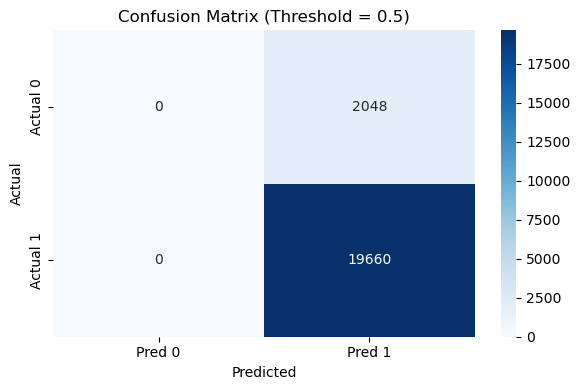

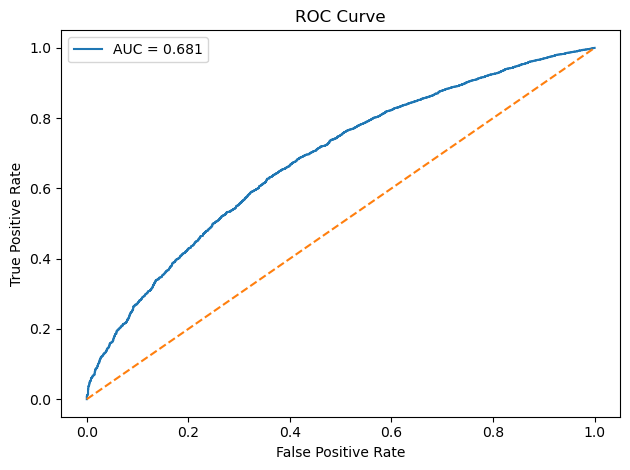

In [2]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# 1. Predict probabilities and class labels (thr=0.5)
# --------------------------------------------------
y_pred_prob = model.predict(X_test)
threshold = 0.5
y_pred = (y_pred_prob >= threshold).astype(int)

# --------------------------------------------------
# 2. Confusion matrix and basic components
# --------------------------------------------------
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# --------------------------------------------------
# 3. Metrics
# --------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)            # TPR
specificity = tn / (tn + fp)                     # TNR
fpr_rate = fp / (fp + tn)                        # False Positive Rate
fnr = fn / (fn + tp)                             # False Negative Rate
f1 = f1_score(y_test, y_pred)
balanced_accuracy = (recall + specificity) / 2
auc = roc_auc_score(y_test, y_pred_prob)

# --------------------------------------------------
# 4. Print metrics
# --------------------------------------------------
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall (TPR): {recall:.4f}")
print(f"Specificity (TNR): {specificity:.4f}")
print(f"False Positive Rate (FPR): {fpr_rate:.4f}")
print(f"False Negative Rate (FNR): {fnr:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"AUC-ROC: {auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

# --------------------------------------------------
# 5. Confusion Matrix Heatmap
# --------------------------------------------------
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title(f"Confusion Matrix (Threshold = {threshold})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. ROC Curve
# --------------------------------------------------
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

## Analysis to select the best threshold

In [3]:

# List of thresholds to evaluate
thresholds = np.arange(0.1, 0.91, 0.1)  # 0.1, 0.2, ..., 0.9

rows = []

for thr in thresholds:
    y_pred = (y_pred_prob >= thr).astype(int)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    rows.append({
        "threshold": thr,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df)


   threshold  accuracy  precision    recall        f1    TN    FP    FN     TP
0        0.1  0.905657   0.905657  1.000000  0.950493     0  2048     0  19660
1        0.2  0.905657   0.905657  1.000000  0.950493     0  2048     0  19660
2        0.3  0.905657   0.905657  1.000000  0.950493     0  2048     0  19660
3        0.4  0.905657   0.905657  1.000000  0.950493     0  2048     0  19660
4        0.5  0.905657   0.905657  1.000000  0.950493     0  2048     0  19660
5        0.6  0.905703   0.905699  1.000000  0.950516     1  2047     0  19660
6        0.7  0.902985   0.906719  0.995270  0.948933    35  2013    93  19567
7        0.8  0.875438   0.914572  0.951322  0.932585   301  1747   957  18703
8        0.9  0.673346   0.940430  0.682553  0.791005  1198   850  6241  13419


In [4]:
import pandas as pd

# Create table from your threshold results
data = {
    "threshold": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    "accuracy": [0.905657, 0.905657, 0.905657, 0.905657, 0.905657, 0.905703, 0.902985, 0.875438, 0.673346],
    "precision": [0.905657, 0.905657, 0.905657, 0.905657, 0.905657, 0.905699, 0.906719, 0.914572, 0.940430],
    "recall": [1.000000, 1.000000, 1.000000, 1.000000, 1.000000, 1.000000, 0.995270, 0.951322, 0.682553],
    "f1": [0.950493, 0.950493, 0.950493, 0.950493, 0.950493, 0.950516, 0.948933, 0.932585, 0.791005],
    "TN": [0, 0, 0, 0, 0, 1, 35, 301, 1198],
    "FP": [2048, 2048, 2048, 2048, 2048, 2047, 2013, 1747, 850],
    "FN": [0, 0, 0, 0, 0, 0, 93, 957, 6241],
    "TP": [19660, 19660, 19660, 19660, 19660, 19660, 19567, 18703, 13419],
}

df_thr = pd.DataFrame(data)
df_thr


,threshold,accuracy,precision,recall,f1,TN,FP,FN,TP
0,0.1,0.905657,0.905657,1.000000,0.950493,0,2048,0,19660
1,0.2,0.905657,0.905657,1.000000,0.950493,0,2048,0,19660
2,0.3,0.905657,0.905657,1.000000,0.950493,0,2048,0,19660
3,0.4,0.905657,0.905657,1.000000,0.950493,0,2048,0,19660
4,0.5,0.905657,0.905657,1.000000,0.950493,0,2048,0,19660
5,0.6,0.905703,0.905699,1.000000,0.950516,1,2047,0,19660
6,0.7,0.902985,0.906719,0.995270,0.948933,35,2013,93,19567
7,0.8,0.875438,0.914572,0.951322,0.932585,301,1747,957,18703
8,0.9,0.673346,0.940430,0.682553,0.791005,1198,850,6241,13419


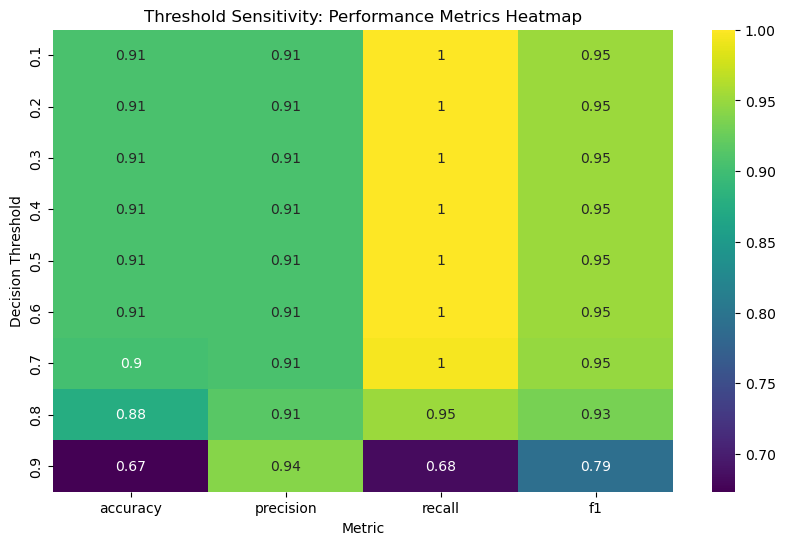

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only metric columns for the heatmap
metrics = df_thr[["accuracy", "precision", "recall", "f1"]]

plt.figure(figsize=(10, 6))
sns.heatmap(metrics, annot=True, cmap="viridis", xticklabels=True, yticklabels=df_thr["threshold"])
plt.title("Threshold Sensitivity: Performance Metrics Heatmap")
plt.xlabel("Metric")
plt.ylabel("Decision Threshold")
plt.show()


## Sensitivity Analysis - Understanding marginal effects of input variables

In [6]:
# Consistent color and figure style
LIGHT_BLUE = "#8ecae6"

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.2
plt.rcParams["font.size"] = 11

# Helper for bar plots
def plot_bar(labels, values, title, ylabel="Predicted probability of severe disposition"):
    plt.figure()
    plt.bar(labels, values, color=LIGHT_BLUE)
    plt.ylabel(ylabel)
    plt.ylim(0, 1)  # probabilities
    plt.title(title)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

In [7]:
# Baseline row: mean of training predictors
base = X_train.mean().copy()


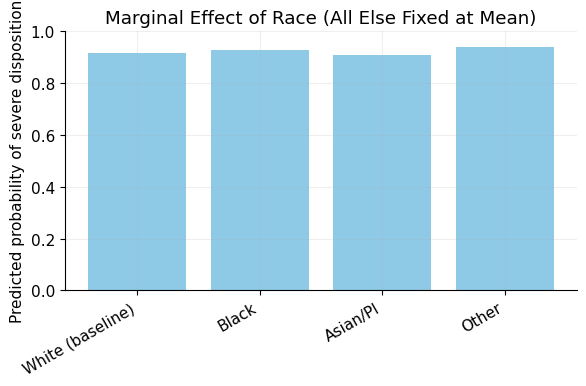

In [8]:
race_cols = [
    "subject_race_black",
    "subject_race_asian/pacific islander",
    "subject_race_other"
]

def predict_for_race(race: str) -> float:
    """race: 'white', 'black', 'asian', or 'other'."""
    x = base.copy()

    # reset all race dummies to 0
    for c in race_cols:
        if c in x.index:
            x[c] = 0

    if race == "black":
        x["subject_race_black"] = 1
    elif race == "asian":
        x["subject_race_asian/pacific islander"] = 1
    elif race == "other":
        x["subject_race_other"] = 1
    # 'white' means all 0s

    # statsmodels expects 2D (1 row)
    pred = model.predict(x.to_frame().T)[0]
    return pred

race_labels = ["White (baseline)", "Black", "Asian/PI", "Other"]
preds_race = [
    predict_for_race("white"),
    predict_for_race("black"),
    predict_for_race("asian"),
    predict_for_race("other")
]

plot_bar(race_labels, preds_race,
         title="Marginal Effect of Race (All Else Fixed at Mean)")


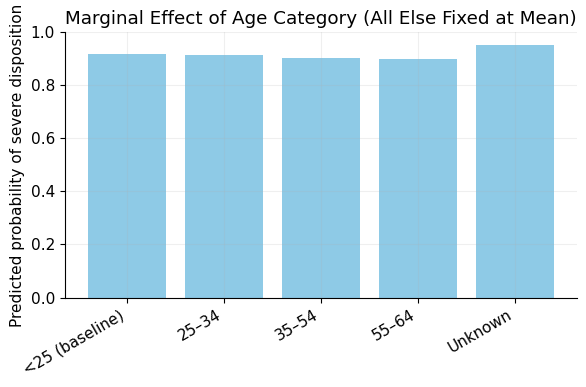

In [9]:
age_cols = [
    "age_category_25-34",
    "age_category_35-54",
    "age_category_55-64",
    "age_category_Unknown"
]

def predict_for_age(age: str) -> float:
    x = base.copy()
    # reset age dummies
    for c in age_cols:
        if c in x.index:
            x[c] = 0

    if age == "25-34":
        x["age_category_25-34"] = 1
    elif age == "35-54":
        x["age_category_35-54"] = 1
    elif age == "55-64":
        x["age_category_55-64"] = 1
    elif age == "Unknown":
        x["age_category_Unknown"] = 1
    # baseline (e.g. <25) = all 0s

    return model.predict(x.to_frame().T)[0]

age_labels = ["<25 (baseline)", "25–34", "35–54", "55–64", "Unknown"]
preds_age = [
    predict_for_age("baseline") if False else predict_for_age("25-34")*0  # just placeholder to keep structure
]

# Build explicitly:
preds_age = [
    model.predict(base.to_frame().T)[0],   # baseline: all age dummies 0
    predict_for_age("25-34"),
    predict_for_age("35-54"),
    predict_for_age("55-64"),
    predict_for_age("Unknown")
]

plot_bar(age_labels, preds_age,
         title="Marginal Effect of Age Category (All Else Fixed at Mean)")


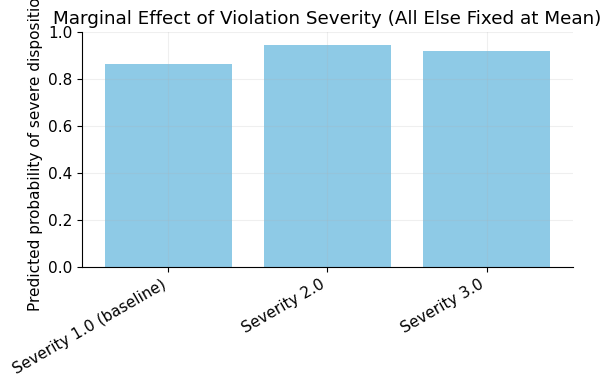

In [10]:
sev_cols = ["violation_severity_2.0", "violation_severity_3.0"]

def predict_for_severity(level: int) -> float:
    x = base.copy()
    for c in sev_cols:
        if c in x.index:
            x[c] = 0

    if level == 2:
        x["violation_severity_2.0"] = 1
    elif level == 3:
        x["violation_severity_3.0"] = 1
    # level 1 = both 0

    return model.predict(x.to_frame().T)[0]

sev_labels = ["Severity 1.0 (baseline)", "Severity 2.0", "Severity 3.0"]
preds_sev = [
    predict_for_severity(1),
    predict_for_severity(2),
    predict_for_severity(3)
]

plot_bar(sev_labels, preds_sev,
         title="Marginal Effect of Violation Severity (All Else Fixed at Mean)")


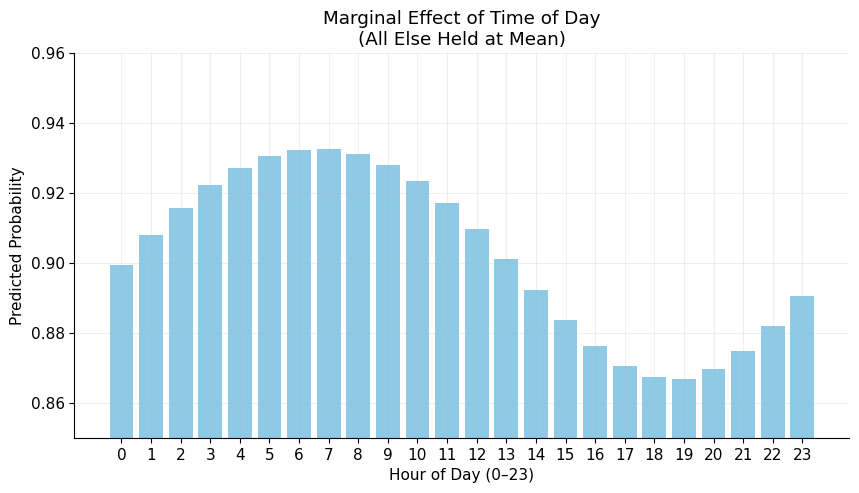

In [13]:

baseline = X_train.mean().copy()

# Drop hour sin/cos because we will overwrite them
baseline['hour_sin'] = 0
baseline['hour_cos'] = 0

# ---------------------------
# 3. Compute predicted prob. for each hour
# ---------------------------
hours = np.arange(24)
predictions = []

for h in hours:
    temp_row = baseline.copy()

    # Insert correct sinusoidal transforms
    temp_row['hour_sin'] = np.sin(2 * np.pi * h / 24)
    temp_row['hour_cos'] = np.cos(2 * np.pi * h / 24)

    # Predict probability
    prob = model.predict(temp_row.to_frame().T)[0]
    predictions.append(prob)

# ---------------------------
# 4. Plot as BAR CHART
# ---------------------------
plt.figure(figsize=(10, 5))
plt.bar(hours, predictions, color=LIGHT_BLUE)
plt.xticks(hours)
plt.ylabel("Predicted Probability")
plt.xlabel("Hour of Day (0–23)")
plt.title("Marginal Effect of Time of Day\n(All Else Held at Mean)")
plt.ylim(0.85, 0.96)  # adjust based on your model's scale
plt.show()


## Sensitivity Analysis - Understanding the effect post dropping input variables one at a time

In [48]:
vars_to_test = X_train.columns.drop('Unnamed: 0')

for var in vars_to_test:
    X_tmp = X_train.drop(columns=[var])
    mod = sm.GLM(y_train, X_tmp, sm.families.Binomial()).fit()
    print(var, mod.params.get(var, "dropped"), mod.aic)

const dropped 38803.70987209073
subject_race_black dropped 38736.61996511383
subject_race_asian/pacific islander dropped 38725.00037198076
subject_race_other dropped 38725.37856541715
vehicle_tier_LUXURY dropped 38742.202137956156
vehicle_tier_MID dropped 38730.30960889213
vehicle_tier_UNKNOWN dropped 38740.23896271606
violation_severity_2.0 dropped 39699.43206629196
violation_severity_3.0 dropped 38901.83953002986
city_location_east dropped 38736.47363810304
city_location_north dropped 38734.74906700615
city_location_south dropped 38738.95033340377
city_location_unknown dropped 38762.70164461064
city_location_west dropped 38725.05751449187
age_category_25-34 dropped 38725.4927040527
age_category_35-54 dropped 38744.01475088552
age_category_55-64 dropped 38741.77772903608
age_category_Unknown dropped 38838.977728908816
year_cat_2019 dropped 38775.10039155568
year_cat_2020 dropped 38753.35694393862
hour_sin dropped 39056.15328878378
hour_cos dropped 38731.28374223844
month_sin dropped 3

                               Variable   AIC_dropped    AIC_diff
2   subject_race_asian/pacific islander  38725.000372   -1.546810
13                   city_location_west  38725.057514   -1.489667
3                    subject_race_other  38725.378565   -1.168616
26                   vehicle_tier_other  38725.481216   -1.065966
14                   age_category_25-34  38725.492704   -1.054478
22                            month_sin  38726.102549   -0.444633
25                              dow_cos  38728.506807    1.959625
5                      vehicle_tier_MID  38730.309609    3.762427
21                             hour_cos  38731.283742    4.736560
23                            month_cos  38731.973772    5.426590
10                  city_location_north  38734.749067    8.201885
9                    city_location_east  38736.473638    9.926456
1                    subject_race_black  38736.619965   10.072783
11                  city_location_south  38738.950333   12.403151
6         

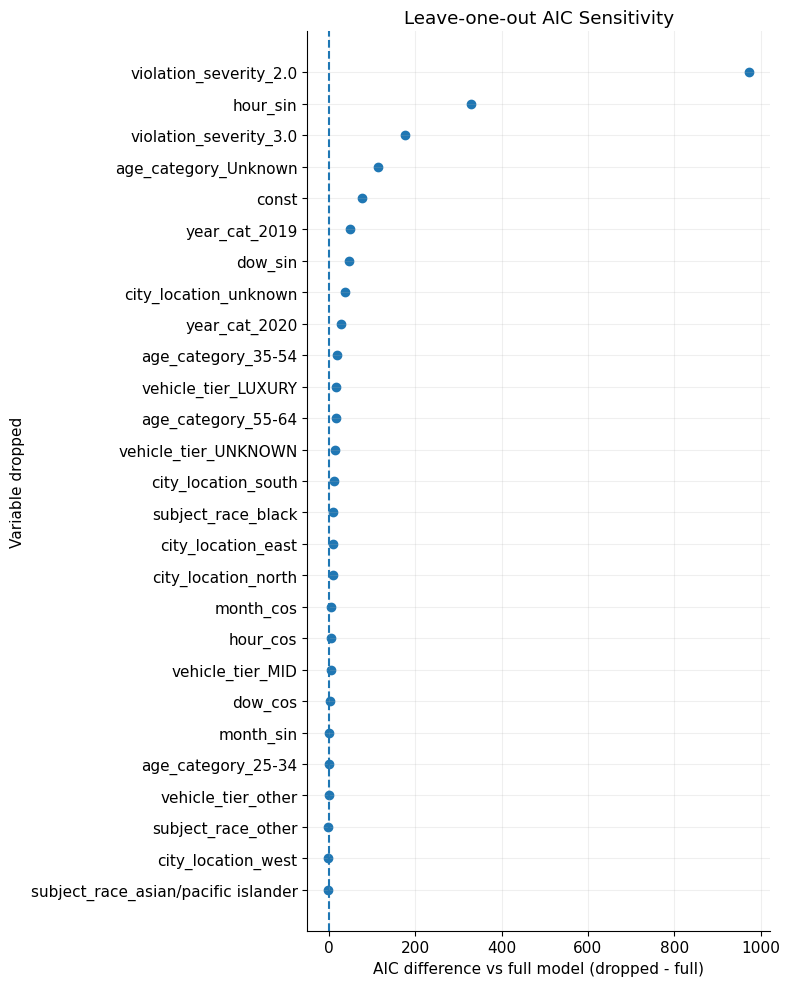

In [49]:
# 1. Full training AIC
full_aic = 38726.54718191056

# 2. AIC when each variable is dropped (your numbers)
aic_drop = pd.DataFrame({
    "Variable": [
        "const",
        "subject_race_black",
        "subject_race_asian/pacific islander",
        "subject_race_other",
        "vehicle_tier_LUXURY",
        "vehicle_tier_MID",
        "vehicle_tier_UNKNOWN",
        "violation_severity_2.0",
        "violation_severity_3.0",
        "city_location_east",
        "city_location_north",
        "city_location_south",
        "city_location_unknown",
        "city_location_west",
        "age_category_25-34",
        "age_category_35-54",
        "age_category_55-64",
        "age_category_Unknown",
        "year_cat_2019",
        "year_cat_2020",
        "hour_sin",
        "hour_cos",
        "month_sin",
        "month_cos",
        "dow_sin",
        "dow_cos",
        "vehicle_tier_other"
    ],
    "AIC_dropped": [
        38803.70987209073,
        38736.61996511383,
        38725.00037198076,
        38725.37856541715,
        38742.202137956156,
        38730.30960889213,
        38740.23896271606,
        39699.43206629196,
        38901.83953002986,
        38736.47363810304,
        38734.74906700615,
        38738.95033340377,
        38762.70164461064,
        38725.05751449187,
        38725.4927040527,
        38744.01475088552,
        38741.77772903608,
        38838.977728908816,
        38775.10039155568,
        38753.35694393862,
        39056.15328878378,
        38731.28374223844,
        38726.10254903585,
        38731.973771968514,
        38773.18121208726,
        38728.506806811456,
        38725.481215809
    ]
})

# 3. Compute AIC difference vs full model
aic_drop["AIC_diff"] = aic_drop["AIC_dropped"] - full_aic

# 4. Sort by AIC_diff (largest increase = most important)
aic_drop_sorted = aic_drop.sort_values("AIC_diff", ascending=True)  # or False if you want biggest first

print(aic_drop_sorted)

# 5. Dot plot (horizontal)
plt.figure(figsize=(8, 10))
plt.scatter(aic_drop_sorted["AIC_diff"], aic_drop_sorted["Variable"])
plt.axvline(0, linestyle="--")  # reference line: no change in AIC
plt.xlabel("AIC difference vs full model (dropped - full)")
plt.ylabel("Variable dropped")
plt.title("Leave-one-out AIC Sensitivity")
plt.tight_layout()
plt.show()

## Scenario Analysis - Combining multiple variables

In [50]:
def set_hour_terms(ser, hour):
    """
    ser : pd.Series (single row of features)
    hour: int or float, in [0, 23]
    """
    hour_rad = 2 * np.pi * hour / 24.0
    if 'hour_sin' in ser.index:
        ser['hour_sin'] = np.sin(hour_rad)
    if 'hour_cos' in ser.index:
        ser['hour_cos'] = np.cos(hour_rad)
    return ser

# Start from means so all columns are present
base = X.mean().copy()

# 1. Race dummies → all zero ⇒ White
race_cols = [
    'subject_race_black',
    'subject_race_asian/pacific islander',
    'subject_race_other'
]
for c in race_cols:
    if c in base.index:
        base[c] = 0.0

# 2. Violation severity → baseline (severity 1.0)
for c in ['violation_severity_2.0', 'violation_severity_3.0']:
    if c in base.index:
        base[c] = 0.0

# 3. Age dummies → all zero (reference age)
age_cols = [
    'age_category_25-34',
    'age_category_35-54',
    'age_category_55-64',
    'age_category_Unknown'
]
for c in age_cols:
    if c in base.index:
        base[c] = 0.0

# 4. Vehicle tiers → reference tier
veh_cols = [
    'vehicle_tier_LUXURY',
    'vehicle_tier_MID',
    'vehicle_tier_UNKNOWN',
    'vehicle_tier_other'
]
for c in veh_cols:
    if c in base.index:
        base[c] = 0.0

# 5. Choose a “low-risk” hour (say 14:00) and overwrite hour_sin/cos
base = set_hour_terms(base, hour=14)

# Finally, make it a 1-row DataFrame
base_df = pd.DataFrame([base])

In [51]:
scenarios = {}

# White baseline (all race dummies 0)
white_row = base_df.copy()
scenarios['White'] = white_row

# Black scenario: same as baseline, but Black = 1
black_row = base_df.copy()
black_row['subject_race_black'] = 1.0
scenarios['Black'] = black_row

# Asian / Pacific Islander
asian_row = base_df.copy()
asian_row['subject_race_asian/pacific islander'] = 1.0
scenarios['Asian/PI'] = asian_row

# Other race
other_row = base_df.copy()
other_row['subject_race_other'] = 1.0
scenarios['Other'] = other_row

# Combine to one DataFrame
scenarios_df = pd.concat(scenarios, names=['Race', 'row']).reset_index(level='row', drop=True)
print(scenarios_df)


          const     Unnamed: 0  subject_race_black  \
Race                                                 
White       1.0  978130.459104                 0.0   
Black       1.0  978130.459104                 1.0   
Asian/PI    1.0  978130.459104                 0.0   
Other       1.0  978130.459104                 0.0   

          subject_race_asian/pacific islander  subject_race_other  \
Race                                                                
White                                     0.0                 0.0   
Black                                     0.0                 0.0   
Asian/PI                                  1.0                 0.0   
Other                                     0.0                 1.0   

          vehicle_tier_LUXURY  vehicle_tier_MID  vehicle_tier_UNKNOWN  \
Race                                                                    
White                     0.0               0.0                   0.0   
Black                     0.0            

In [52]:
race_preds = model.predict(scenarios_df)
race_results = pd.DataFrame({
    'Race': race_preds.index,
    'Predicted_prob_severe': race_preds.values
})
print(race_results)


       Race  Predicted_prob_severe
0     White               0.825216
1     Black               0.851578
2  Asian/PI               0.814180
3     Other               0.869939


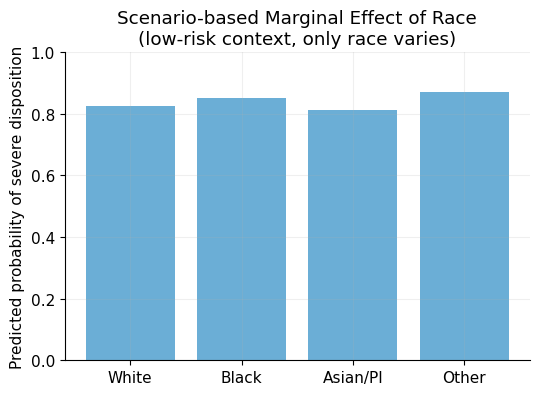

In [53]:
import matplotlib.pyplot as plt

plt.figure()
plt.bar(race_results['Race'], race_results['Predicted_prob_severe'], color = LIGHT_BLUE)
plt.ylim(0, 1)
plt.ylabel("Predicted probability of severe disposition")
plt.title("Scenario-based Marginal Effect of Race\n(low-risk context, only race varies)")
plt.show()
